# Data Overview and Spike Definition

## Objective

This notebook explores the master dataset and establishes the definition of an imbalance price spike used throughout the thesis (Objective O1). The definition determines which periods are treated as rare events, and therefore underpins every later model and sensitivity analysis.

## Data

- **Source:** `master.parquet`, built by `src/data_prep.py` from the raw extracts
- **Period:** 1 February 2022 to 30 September 2026, half-hourly (UTC)
- **Key variables:** imbalance price `pimb_eur` (€/MWh), day-ahead price `da_price_eur` (€/MWh), net imbalance volume `niv_mwh` (MWh)

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from config.paths import PROCESSED_DIR

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.2,
    "legend.frameon": False,
})

FIG_DIR = Path.cwd().parent / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVE = False   # set True to write every figure to outputs/figures as PDF

def finish(fig, name):
    fig.tight_layout()
    if SAVE:
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()

def to_local(idx):
    # Timezone-naive Irish local time, for plotting.
    return idx.tz_convert("Europe/Dublin").tz_localize(None)

df = pd.read_parquet(PROCESSED_DIR / "master.parquet").set_index("time_utc")
df.index.min(), df.index.max(), df.shape

(Timestamp('2022-02-01 00:00:00+0000', tz='UTC'),
 Timestamp('2026-09-30 23:30:00+0000', tz='UTC'),
 (81744, 17))

## 1. The spike variable: the PIMB–DA spread

> **Definition (spread)**
>
> $$S_t = P^{\text{IMB}}_t - P^{\text{DA}}_t$$
>
> where $P^{\text{IMB}}_t$ is the imbalance price and $P^{\text{DA}}_t$ the day-ahead price for settlement period $t$.

Spikes are defined on the spread rather than on the imbalance price itself. The imbalance price follows the day-ahead price, which carries the gas-driven price level and the daily demand shape. Subtracting the day-ahead price for the same period removes both, so that:

- a spike reflects balancing conditions rather than a high day-ahead price,
- it measures the exposure of a participant who traded at the day-ahead price, and
- spikes are comparable across periods of high and low gas prices and across hours of the day.

The forecasting target remains the imbalance price; the spread is used only to label spikes.

In [2]:
df["spread"] = df["pimb_eur"] - df["da_price_eur"]

cols = ["pimb_eur", "da_price_eur", "spread", "niv_mwh"]
summary = df[cols].describe(percentiles=[.01, .05, .5, .95, .99]).T
summary["missing_%"] = df[cols].isna().mean() * 100
summary

,count,mean,std,min,1%,5%,50%,95%,99%,max,missing_%
pimb_eur,"81,445.00",140.10,108.33,-411.72,-15.67,0.00,124.14,361.47,488.06,874.25,0.37
da_price_eur,"81,744.00",141.83,80.50,-30.00,1.00,48.62,121.40,304.10,430.00,705.47,0.00
spread,"81,445.00",-1.67,77.57,-478.54,-167.67,-109.89,-11.71,124.57,248.32,465.13,0.37
niv_mwh,"80,960.00",1.06,27.12,-238.00,-71.90,-42.06,1.13,44.41,66.93,193.16,0.96


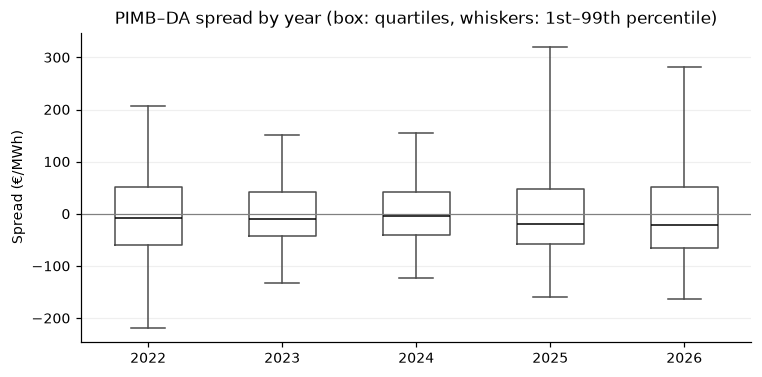

,periods,mean,std,1%,5%,25%,50%,75%,95%,99%,iqr,p99_p01_range
time_utc,,,,,,,,,,,,
2022,"15,996.00",-5.70,87.00,-218.00,-143.90,-60.30,-8.80,50.70,133.30,207.20,111.10,425.20
2023,"17,484.00",-2.40,60.40,-132.20,-93.30,-42.70,-9.70,41.40,96.30,151.60,84.20,283.80
2024,"17,508.00",1.30,59.40,-124.10,-83.00,-39.70,-4.00,42.60,93.30,154.60,82.40,278.80
2025,"17,478.00",1.50,89.10,-159.70,-103.50,-57.40,-18.70,48.40,167.80,320.10,105.80,479.80
2026,"12,979.00",-4.20,89.60,-163.20,-121.30,-66.20,-22.40,50.90,162.00,281.10,117.10,444.30


In [3]:
spread = df["spread"].dropna()
by_year = spread.groupby(spread.index.year)
years = list(by_year.groups)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([g.values for _, g in by_year], tick_labels=years, whis=(1, 99), showfliers=False,
           medianprops=dict(color="black"), boxprops=dict(color="0.3"),
           whiskerprops=dict(color="0.3"), capprops=dict(color="0.3"))
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("Spread (€/MWh)")
ax.set_title("PIMB–DA spread by year (box: quartiles, whiskers: 1st–99th percentile)")
finish(fig, "spread_by_year")

stats = by_year.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
stats["iqr"] = stats["75%"] - stats["25%"]
stats["p99_p01_range"] = stats["99%"] - stats["1%"]
stats = stats.rename(columns={"count": "periods"})
stats[["periods", "mean", "std", "1%", "5%", "25%", "50%", "75%", "95%", "99%", "iqr", "p99_p01_range"]].round(1)

## 2. Spike definitions

**Rolling threshold.** A period is a spike if the spread is extreme relative to recent market conditions.

> **Definition (rolling)**
>
> $$\text{spike}^{+}_t = \mathbb{1}\left[S_t > q^{W}_{0.99,\,t}\right], \qquad \text{spike}^{-}_t = \mathbb{1}\left[S_t < q^{W}_{0.01,\,t}\right]$$
>
> where $q^{W}_{\alpha,\,t}$ is the $\alpha$-quantile of $S$ over the trailing window $[\,t - W,\; t\,)$. The 95th and 5th percentiles define less extreme events in the same way.

**Fixed threshold.** The same quantiles estimated once over the whole sample. This treats a spike as a deviation of a given size in €/MWh, whenever it occurs, and serves as the benchmark.

Candidate rolling windows of 30, 60, 90 and 365 days are compared below, and one is chosen as the primary definition.

**Design choices common to all rolling definitions**

- **Trailing window only.** Each threshold uses only periods before $t$, so no information from after the labelled period is used. This is a stricter form of estimating thresholds from training data only.
- **Warm-up.** Data before 1 February 2022 belongs to the previous market design and is not used. A window requires 30 days of data, or 80% of its length if shorter, before producing a threshold; until a full window is available it covers all data since the start of the sample. February 2022 is unlabelled.
- **Quantiles, not mean plus $k$ standard deviations.** The mean and variance are themselves distorted by spikes (Janczura et al., 2013).
- **One threshold for all hours of the day.** Hour-specific thresholds would leave too few observations per threshold and would remove any genuine time-of-day pattern in balancing stress, which is a result to be found rather than assumed away. Time of day enters the models as an input instead.
- **Positive and negative tails are treated separately**, as their drivers differ (Hagfors et al., 2016).

In [4]:
QUANTILES = {"p01": 0.01, "p05": 0.05, "p95": 0.95, "p99": 0.99}

def fixed_thresholds(s):
    # Whole-sample quantiles, repeated for every period.
    return pd.DataFrame({k: s.quantile(q) for k, q in QUANTILES.items()}, index=s.index)

def rolling_thresholds(s, window, min_days=30):
    # Trailing quantiles over `window`, using only periods before t.
    # Requires min(min_days, 80% of the window) of data, so gaps in the data
    # don't blank out short windows. Until a full window exists, the window covers
    # all data since the start of the sample.
    days = pd.Timedelta(window).days
    r = s.rolling(window, min_periods=int(min(min_days, 0.8 * days) * 48))
    return pd.DataFrame({k: r.quantile(q) for k, q in QUANTILES.items()}).shift(1)

def with_floor(thr, floor_up, floor_down):
    # Upper thresholds no lower than floor_up, lower thresholds no higher than floor_down.
    out = thr.copy()
    out[["p95", "p99"]] = out[["p95", "p99"]].clip(lower=floor_up)
    out[["p01", "p05"]] = out[["p01", "p05"]].clip(upper=floor_down)
    return out

def label_spikes(s, thr):
    # Boolean spike flags; missing where the spread or the threshold is missing.
    out = pd.DataFrame({
        "up_99": s > thr["p99"], "up_95": s > thr["p95"],
        "down_05": s < thr["p05"], "down_01": s < thr["p01"],
    }).astype("boolean")
    out[~(s.notna() & thr["p99"].notna())] = pd.NA
    return out

In [5]:
s = df["spread"]
thresholds = {
    "fixed": fixed_thresholds(s),
    "roll_30d": rolling_thresholds(s, "30D"),
    "roll_60d": rolling_thresholds(s, "60D"),
    "roll_90d": rolling_thresholds(s, "90D"),
    "roll_365d": rolling_thresholds(s, "365D"),
}
labels = {name: label_spikes(s, thr) for name, thr in thresholds.items()}

### Choice of rolling window

The window length trades off two properties:

- **Adaptation:** a well-adapted threshold labels close to the nominal 1% of periods as spikes in every month. This is measured by the average distance of the monthly spike rate from 1%, and by the worst month.
- **Stability:** a short window estimates the 99th percentile from few extreme observations (about 14 periods for 30 days), so the threshold moves more from day to day. This is measured by the 95th percentile of the daily change in the threshold.

Windows from 30 to 180 days are evaluated from June 2022, after the first months in which every window is still filling.

In [6]:
WINDOWS = [30, 45, 60, 90, 120, 180]   # days
EVAL_START = "2022-06-01"

def window_diagnostics(s, days):
    thr = rolling_thresholds(s, f"{days}D")
    valid = s.notna() & thr["p99"].notna() & (s.index >= pd.Timestamp(EVAL_START, tz="UTC"))
    up, down = (s > thr["p99"])[valid], (s < thr["p01"])[valid]
    month = lambda f: f.groupby(f.index.tz_convert(None).to_period("M")).mean() * 100
    m_up, m_down = month(up), month(down)
    daily_p99 = thr["p99"][valid].resample("D").last()
    return {
        "periods_above_p99_in_window": round(days * 48 * 0.01),
        "monthly_rate_dev_upper": (m_up - 1).abs().mean(),
        "monthly_rate_dev_lower": (m_down - 1).abs().mean(),
        "worst_month_upper_%": m_up.max(),
        "worst_month_lower_%": m_down.max(),
        "p99_daily_change_p95_eur": daily_p99.diff().abs().quantile(0.95),
    }, m_up

results, monthly_up = {}, {}
for d in WINDOWS:
    results[d], monthly_up[d] = window_diagnostics(s, d)

window_table = pd.DataFrame(results).T.rename_axis("window_days")
window_table.round(2)

,periods_above_p99_in_window,monthly_rate_dev_upper,monthly_rate_dev_lower,worst_month_upper_%,worst_month_lower_%,p99_daily_change_p95_eur
window_days,,,,,,
30,14.00,0.54,0.50,2.81,3.10,14.99
45,22.00,0.63,0.62,3.23,3.30,10.71
60,29.00,0.63,0.67,3.57,3.58,7.91
90,43.00,0.64,0.75,4.31,4.21,5.32
120,58.00,0.67,0.80,4.98,4.63,4.20
180,86.00,0.79,0.81,4.85,4.98,3.28


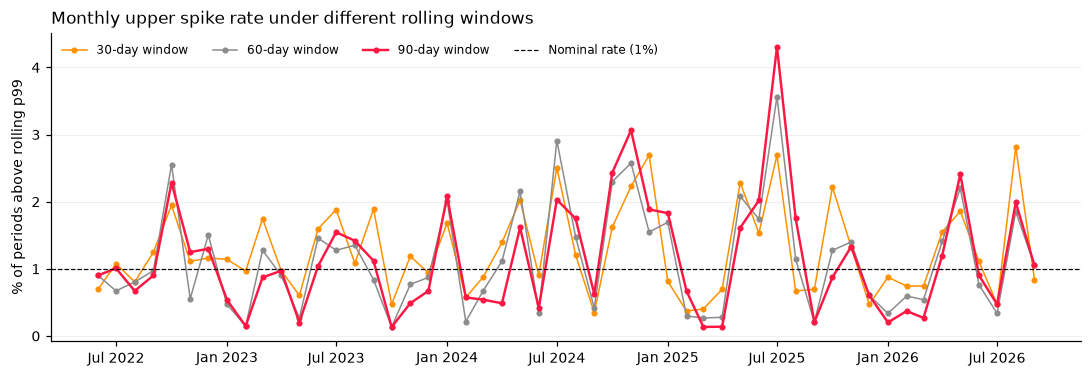

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
styles = {30: ("#ff9100", 1.0), 60: ("0.55", 1.0), 90: ("#ff1744", 1.6)}
for d, (colour, lw) in styles.items():
    m = monthly_up[d]
    ax.plot(m.index.to_timestamp(), m.values, color=colour, lw=lw, marker="o", ms=3, label=f"{d}-day window")
ax.axhline(1, color="black", lw=0.8, ls="--", label="Nominal rate (1%)")
ax.set_ylabel("% of periods above rolling p99")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Monthly upper spike rate under different rolling windows", loc="left")
ax.legend(ncol=4, fontsize=8)
finish(fig, "window_choice_monthly_rate")

In [8]:
def overlap(a, b):
    a, b = a.dropna().astype(bool), b.dropna().astype(bool)
    a, b = a.align(b, join="inner")
    return (a & b).sum() / (a | b).sum()

shared = lambda a, b: (a.fillna(False) & b.fillna(False)).sum() / a.fillna(False).sum()

l60, l90 = labels["roll_60d"], labels["roll_90d"]
print(f"Jaccard overlap 60d vs 90d: upper {overlap(l60['up_99'], l90['up_99']):.2f}, "
      f"lower {overlap(l60['down_01'], l90['down_01']):.2f}")
print(f"Share of 90-day upper spikes that are also 60-day spikes: {shared(l90['up_99'], l60['up_99']):.0%}")

local_hour = lambda f: f[f.fillna(False).astype(bool)].index.tz_convert("Europe/Dublin").hour
for name, lab in [("60d", l60), ("90d", l90)]:
    up = lab["up_99"].fillna(False).astype(bool)
    print(f"{name}: median NIV in upper spikes {df.loc[up, 'niv_mwh'].median():.1f} MWh, "
          f"share in 16:00–21:00 {local_hour(lab['up_99']).isin(range(16, 21)).mean():.0%}")

Jaccard overlap 60d vs 90d: upper 0.79, lower 0.77
Share of 90-day upper spikes that are also 60-day spikes: 89%
60d: median NIV in upper spikes 32.1 MWh, share in 16:00–21:00 33%
90d: median NIV in upper spikes 33.2 MWh, share in 16:00–21:00 34%


**Conclusion.** Shorter windows adapt better: the 30-day window keeps the monthly spike rate closest to 1% (average deviation 0.54 percentage points, worst month 2.8%), while the 180-day window lags behind changes in regime (0.79, worst month 4.9%). Shorter windows are also less stable: the 30-day threshold changes by up to about €15/MWh from one day to the next, as its 99th percentile rests on about 14 extreme periods.

Between 45 and 90 days, adaptation is almost unchanged (average deviation 0.63–0.64 percentage points in the upper tail), while stability improves steadily with window length. The **90-day window** is therefore adopted as the primary definition. Its 99th percentile rests on about 43 extreme periods, its daily change is about a third of that of the 30-day window, and it has a natural interpretation: a spike is extreme relative to the current season. Its adaptation is slightly weaker than that of the 60-day window in the worst month (4.3% against 3.6%), a difference driven largely by a single month (July 2025).

The choice between 60 and 90 days has little effect on which periods are labelled: the two definitions share about 88% of their upper spikes, with the same NIV and time-of-day profile. The fixed definition is retained as a benchmark, and the 30-, 60- and 365-day windows as sensitivity cases.

In [9]:
PRIMARY = "roll_90d"

FLOOR_UP, FLOOR_DOWN = 100, -100   # €/MWh; placeholder, to be justified or removed
thresholds[f"{PRIMARY}_floor"] = with_floor(thresholds[PRIMARY], FLOOR_UP, FLOOR_DOWN)
labels[f"{PRIMARY}_floor"] = label_spikes(s, thresholds[f"{PRIMARY}_floor"])

### Economic floor

A rolling threshold can label small deviations as spikes in calm periods. An optional economic floor $c$ requires a spike to also exceed a minimum spread:

$$\text{spike}^{+}_t = \mathbb{1}\left[S_t > \max\left(q^{W}_{0.99,\,t},\; c^{+}\right)\right], \qquad \text{spike}^{-}_t = \mathbb{1}\left[S_t < \min\left(q^{W}_{0.01,\,t},\; c^{-}\right)\right]$$

The values used below (±€100/MWh) are placeholders, to be set with reference to a trading decision or removed. The table after the next cell shows that the floor has essentially no effect on the rare-event labels (99th/1st percentiles), because the 90-day thresholds at those levels stay beyond ±€100/MWh. It affects only the frequent-event labels (95th/5th percentiles), mainly in the calm period of 2023–24, so the decision on the floor concerns those labels only.

In [10]:
base, floored = labels[PRIMARY], labels[f"{PRIMARY}_floor"]
effect = pd.DataFrame({
    "spikes": base.fillna(False).astype(bool).sum(),
    "with_floor": floored.fillna(False).astype(bool).sum(),
})
effect["removed"] = effect["spikes"] - effect["with_floor"]
effect["removed_%"] = (effect["removed"] / effect["spikes"] * 100).round(1)
effect

,spikes,with_floor,removed,removed_%
up_99,913,913,0,0.00
up_95,4212,3639,573,13.60
down_05,4085,3160,925,22.60
down_01,836,818,18,2.20


## 3. Comparing the definitions

The spike rate per year shows how evenly each definition spreads events over time. Under a fixed threshold, spikes concentrate in volatile years; a rolling threshold keeps the rate close to the nominal level in every year.

In [11]:
rate = pd.concat({n: lab.groupby(lab.index.year).mean() * 100 for n, lab in labels.items()}, axis=1)

print("Upper tail (p99), % of periods")
display(rate.xs("up_99", axis=1, level=1).round(2))
print("\nLower tail (p01), % of periods")
display(rate.xs("down_01", axis=1, level=1).round(2))

Upper tail (p99), % of periods


,fixed,roll_30d,roll_60d,roll_90d,roll_365d,roll_90d_floor
time_utc,,,,,,
2022,0.48,1.21,1.13,1.15,1.25,1.15
2023,0.08,1.21,0.82,0.77,0.20,0.77
2024,0.33,1.51,1.49,1.47,1.60,1.47
2025,2.49,1.19,1.22,1.30,2.24,1.30
2026,1.80,1.23,1.01,0.99,0.41,0.99



Lower tail (p01), % of periods


,fixed,roll_30d,roll_60d,roll_90d,roll_365d,roll_90d_floor
time_utc,,,,,,
2022,2.86,1.32,1.24,1.12,0.82,1.12
2023,0.37,1.04,0.82,0.66,0.13,0.66
2024,0.22,1.13,1.22,1.28,1.55,1.18
2025,0.85,1.16,1.03,1.07,1.40,1.07
2026,0.81,1.22,1.16,1.12,1.32,1.12


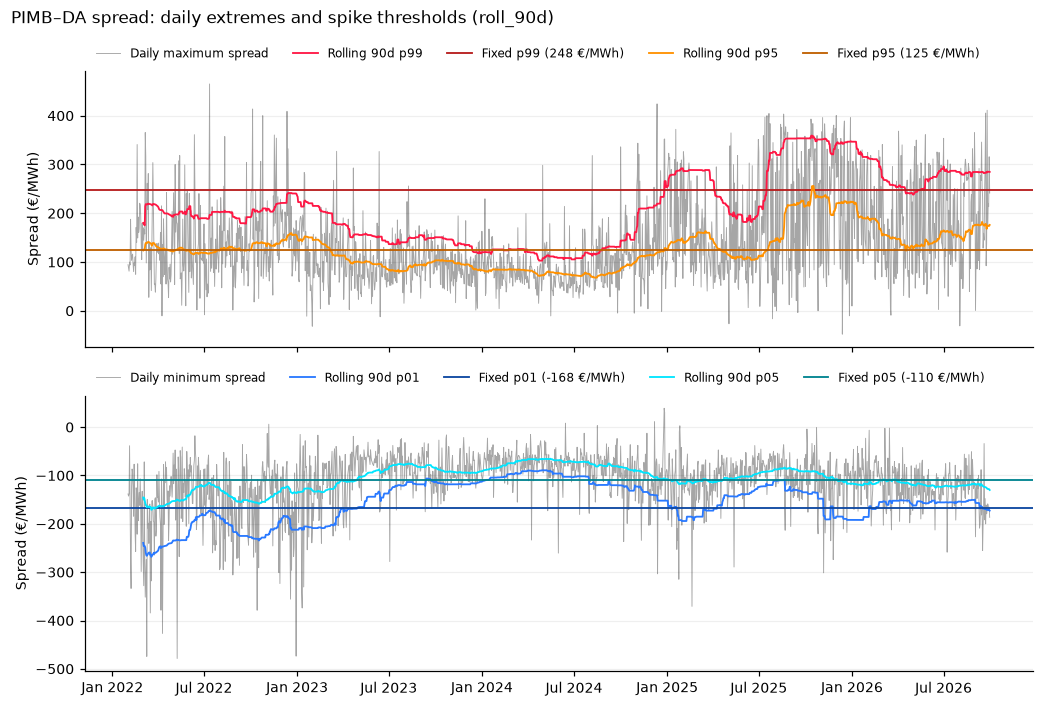

In [12]:
def tail_plot(tail, ax):
    # Daily extremes of the spread against the spike thresholds for one tail.
    if tail == "upper":
        data, stat = s.resample("D").max(), "Daily maximum"
        lines = {"p99": ("#ff1744", "#b71c1c"), "p95": ("#ff9100", "#bf5f00")}
    else:
        data, stat = s.resample("D").min(), "Daily minimum"
        lines = {"p01": ("#2979ff", "#0d47a1"), "p05": ("#00e5ff", "#00838f")}
    thr = thresholds[PRIMARY].resample("D").last()

    ax.plot(to_local(data.index), data, color="black", alpha=0.35, lw=0.6, label=f"{stat} spread")
    for q, (c_roll, c_fixed) in lines.items():
        ax.plot(to_local(thr.index), thr[q], color=c_roll, lw=1.2, label=f"Rolling 90d {q}")
        v = thresholds["fixed"][q].iloc[0]
        ax.axhline(v, color=c_fixed, lw=1.2, label=f"Fixed {q} ({v:.0f} €/MWh)")
    ax.set_ylabel("Spread (€/MWh)")
    ax.legend(ncol=5, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0))

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
tail_plot("upper", axes[0])
tail_plot("lower", axes[1])
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(f"PIMB–DA spread: daily extremes and spike thresholds ({PRIMARY})", x=0.01, ha="left")
finish(fig, "spike_thresholds")

Agreement between definitions is measured by the Jaccard overlap of their spike sets: the number of periods labelled a spike by both, divided by the number labelled by either. Low overlap means the choice of definition changes which events are studied, which is why the definition is carried through the sensitivity analysis (Objective O4).

In [13]:
up = pd.DataFrame({n: lab["up_99"] for n, lab in labels.items()}).dropna()
jaccard = pd.DataFrame({a: {b: (up[a] & up[b]).sum() / (up[a] | up[b]).sum() for b in up} for a in up})
jaccard.round(2)

,fixed,roll_30d,roll_60d,roll_90d,roll_365d,roll_90d_floor
fixed,1.00,0.32,0.34,0.36,0.40,0.36
roll_30d,0.32,1.00,0.66,0.62,0.41,0.62
roll_60d,0.34,0.66,1.00,0.79,0.48,0.79
roll_90d,0.36,0.62,0.79,1.00,0.53,1.00
roll_365d,0.40,0.41,0.48,0.53,1.00,0.53
roll_90d_floor,0.36,0.62,0.79,1.00,0.53,1.00


# 4. Spikes in context

Using this methodology, it would be good to investigate where these spikes appear in relation to the imbalance price.

In [14]:
SPIKE_STYLE = {   # flag: (label, colour, marker)
    "up_99":   ("Upper spike (p99)", "#ff1744", "^"),
    "up_95":   ("Upper spike (p95)", "#ff9100", "^"),
    "down_05": ("Lower spike (p05)", "#00e5ff", "v"),
    "down_01": ("Lower spike (p01)", "#2979ff", "v"),
}

def plot_spikes(start, end, definition=PRIMARY, name=None):
    """PIMB and DA price over a window (Irish dates), with spike periods marked."""
    t0 = pd.Timestamp(start, tz="Europe/Dublin").tz_convert("UTC")
    t1 = pd.Timestamp(end, tz="Europe/Dublin").tz_convert("UTC")
    w = df.loc[t0:t1, ["pimb_eur", "da_price_eur"]]
    lab = labels[definition].loc[t0:t1].fillna(False).astype(bool)
    x = w.index.tz_convert("Europe/Dublin").tz_localize(None)

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(x, w["da_price_eur"], color="0.6", lw=1, drawstyle="steps-post", label="DA price")
    ax.plot(x, w["pimb_eur"], color="black", lw=0.9, drawstyle="steps-post", label="Imbalance price (PIMB)")

    # p95 markers only where the period is not also a p99 spike, so each period has one marker
    only = {"up_99": lab["up_99"], "up_95": lab["up_95"] & ~lab["up_99"],
            "down_01": lab["down_01"], "down_05": lab["down_05"] & ~lab["down_01"]}
    for flag, (text, colour, marker) in SPIKE_STYLE.items():
        m = only[flag].values
        if m.any():
            ax.scatter(x[m], w["pimb_eur"].values[m], color=colour, marker=marker, s=28,
                       edgecolors="white", linewidths=0.5, zorder=3, label=f"{text}: {m.sum()}")

    ax.set_ylabel("€/MWh")
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
    ax.set_title(f"Imbalance and day-ahead prices with spike periods ({definition}), "
                 f"{pd.Timestamp(start):%d %b %Y} to {pd.Timestamp(end):%d %b %Y}", loc="left")
    ax.legend(ncol=3, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.04))
    finish(fig, name or f"spikes_{pd.Timestamp(start):%Y%m%d}")

def busiest_weeks(definition=PRIMARY, flag="up_99", n=5):
    """Weeks (Mon-Sun, Irish time) with the most spikes of one type."""
    f = labels[definition][flag].fillna(False).astype(bool)
    weekly = f.groupby(f.index.tz_convert("Europe/Dublin").tz_localize(None).to_period("W-SUN")).sum()
    return weekly.sort_values(ascending=False).head(n)

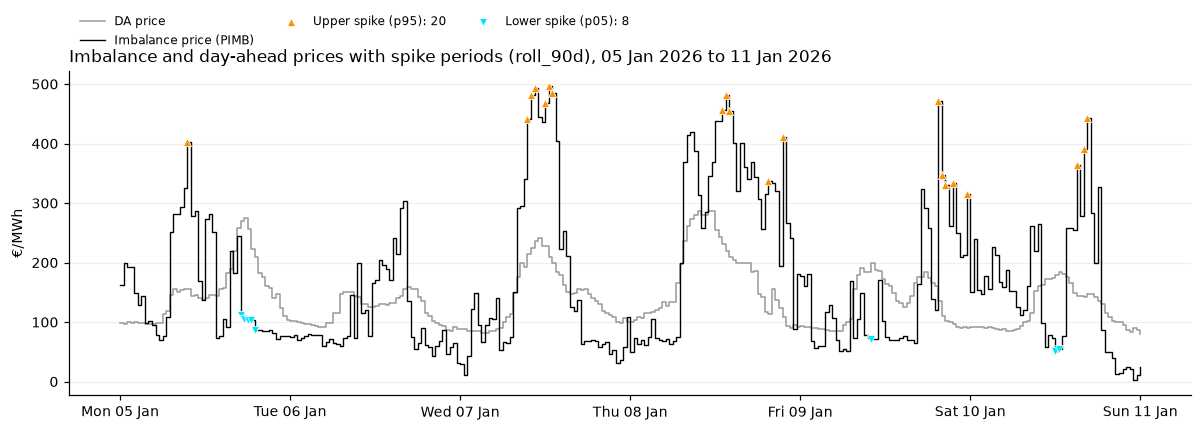

In [27]:
plot_spikes("2026-01-05", "2026-01-11")      # same week as the interim report figure

In [16]:
display(busiest_weeks(flag="up_99"))
display(busiest_weeks(flag="down_01"))

time_utc
2024-11-04/2024-11-10    29
2025-07-14/2025-07-20    22
2022-10-03/2022-10-09    21
2022-03-07/2022-03-13    20
2024-10-28/2024-11-03    20
Freq: W-SUN, Name: up_99, dtype: int64

time_utc
2025-08-18/2025-08-24    33
2024-07-29/2024-08-04    28
2026-09-07/2026-09-13    26
2025-11-03/2025-11-09    25
2025-01-20/2025-01-26    23
Freq: W-SUN, Name: down_01, dtype: int64

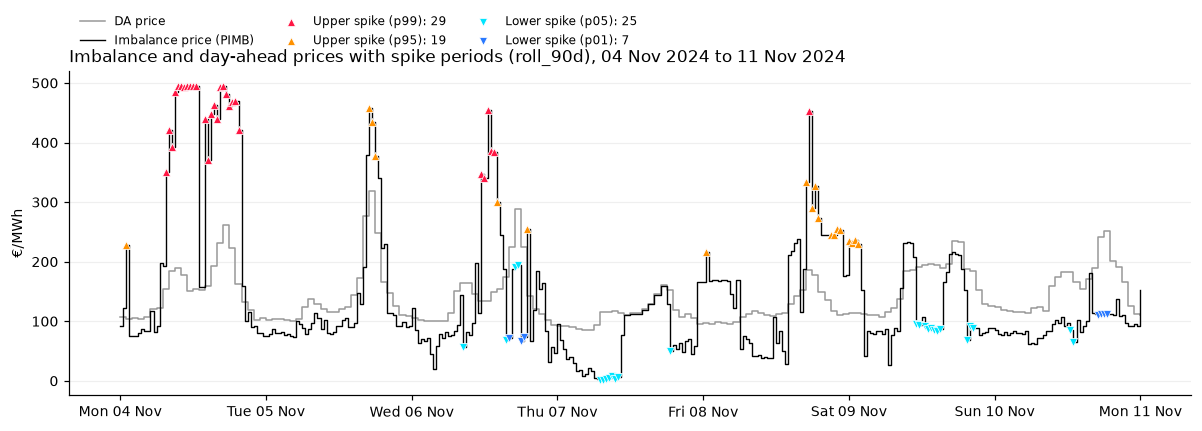

In [17]:
plot_spikes("2024-11-04", "2024-11-11")      # week with the most upper p99 spikes

## 4. When spikes occur

Because the spread already removes the day-ahead daily shape, any remaining concentration of spikes at particular hours or months reflects balancing conditions rather than the demand profile.

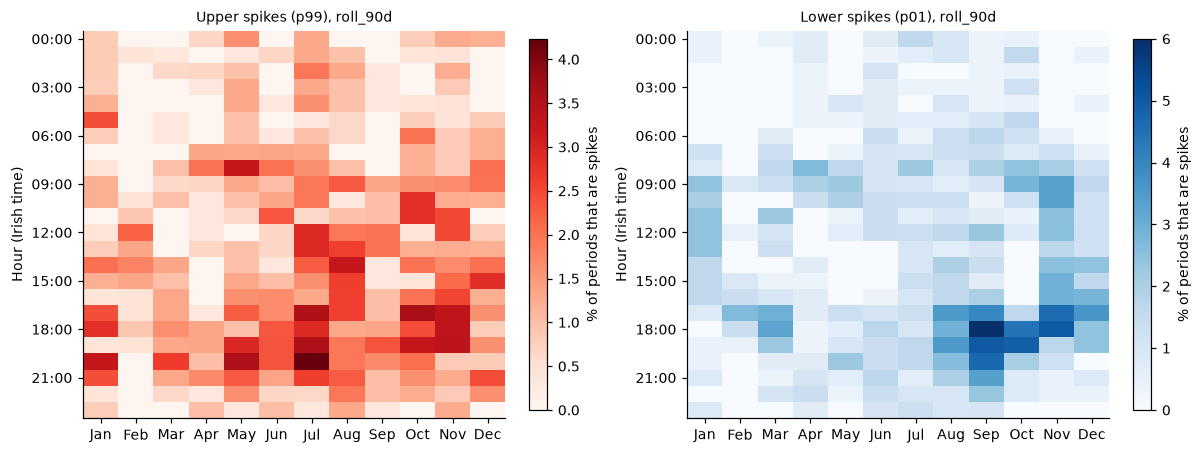

In [18]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def heat_table(flag):
    # % of periods that are spikes, by hour of day (Irish time) and month.
    local = flag.index.tz_convert("Europe/Dublin")
    return (flag.groupby([local.hour, local.month]).mean().unstack() * 100).astype(float)

def spike_heatmap(flag, title, ax, cmap="Reds", vmax=None):
    heat = heat_table(flag)
    im = ax.imshow(heat.values, aspect="auto", cmap=cmap, vmin=0, vmax=vmax, origin="upper")
    ax.set_xticks(range(12), MONTHS)
    ax.set_yticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
    ax.set_ylabel("Hour (Irish time)")
    ax.set_title(title, fontsize=9)
    ax.grid(False)
    plt.colorbar(im, ax=ax, label="% of periods that are spikes", fraction=0.04)
    return heat

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
spike_heatmap(labels[PRIMARY]["up_99"], f"Upper spikes (p99), {PRIMARY}", axes[0], "Reds")
spike_heatmap(labels[PRIMARY]["down_01"], f"Lower spikes (p01), {PRIMARY}", axes[1], "Blues")
finish(fig, "spike_heatmaps")

### Check: spikes on the spread versus on the price

The same rolling definition is applied to the imbalance price itself. If price-based spikes concentrate in the evening peak, they are largely following the day-ahead price shape, which supports using the spread.

Jaccard overlap, upper spikes on spread vs price: 0.30


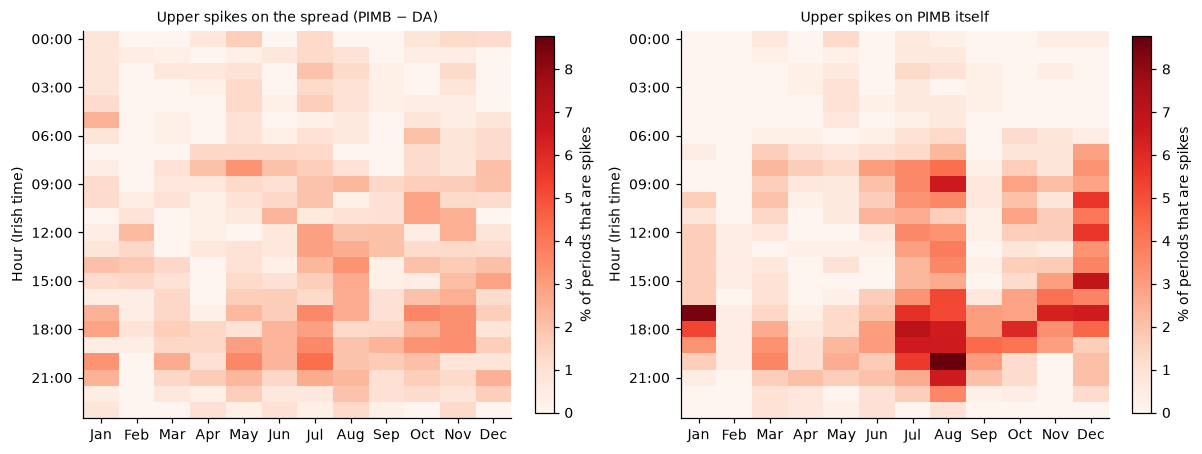

In [19]:
p = df["pimb_eur"]
labels_price = label_spikes(p, rolling_thresholds(p, "90D"))

both = pd.DataFrame({"spread": labels[PRIMARY]["up_99"], "price": labels_price["up_99"]}).dropna()
overlap = (both["spread"] & both["price"]).sum() / (both["spread"] | both["price"]).sum()
print(f"Jaccard overlap, upper spikes on spread vs price: {overlap:.2f}")

vmax = max(heat_table(labels[PRIMARY]["up_99"]).max().max(), heat_table(labels_price["up_99"]).max().max())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
spike_heatmap(labels[PRIMARY]["up_99"], "Upper spikes on the spread (PIMB − DA)", axes[0], vmax=vmax)
spike_heatmap(labels_price["up_99"], "Upper spikes on PIMB itself", axes[1], vmax=vmax)
finish(fig, "spikes_spread_vs_price")

## 5. Spike persistence

Spikes in electricity prices tend to cluster (Christensen et al., 2009). The length of consecutive runs of spike periods indicates whether spikes are isolated events or part of sustained episodes of system stress.

In [20]:
def run_lengths(flag):
    f = flag.fillna(False).astype(bool)
    runs = f.groupby((f != f.shift()).cumsum()).agg(["first", "size"])
    return runs.loc[runs["first"], "size"]

for tail in ["up_99", "down_01"]:
    rl = run_lengths(labels[PRIMARY][tail])
    print(f"{tail}: {len(rl)} runs, mean length {rl.mean():.2f} periods, longest {rl.max()} periods")
    display(rl.value_counts().sort_index().head(10).rename("runs"))

up_99: 470 runs, mean length 1.94 periods, longest 13 periods


size
1     281
2      90
3      40
4      25
5      15
6       6
7       3
8       3
9       2
10      1
Name: runs, dtype: int64

down_01: 396 runs, mean length 2.11 periods, longest 30 periods


size
1     236
2      80
3      24
4      16
5      17
6      11
7       2
8       2
9       1
10      2
Name: runs, dtype: int64

## 6. Relation to the net imbalance volume

The thesis models the chain from renewable and demand uncertainty, through the net imbalance volume, to the imbalance price. A first check of that chain is whether spikes occur in the expected direction of system imbalance: upper spikes when the system is short (positive NIV) and lower spikes when it is long.

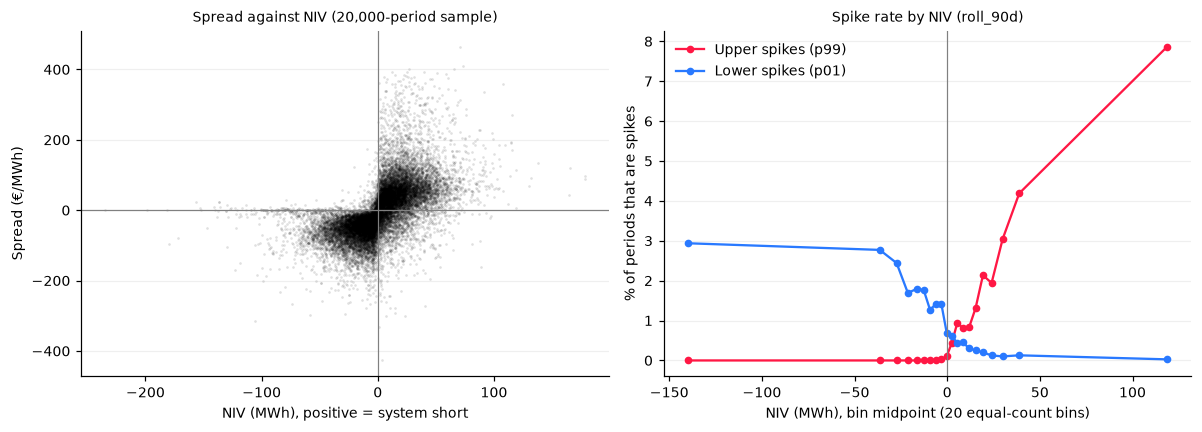

In [21]:
samp = df[["niv_mwh", "spread"]].dropna().sample(20000, random_state=0)
niv_bins = pd.qcut(df["niv_mwh"], 20)
binned = labels[PRIMARY][["up_99", "down_01"]].groupby(niv_bins, observed=True).mean() * 100
mid = [iv.mid for iv in binned.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(samp["niv_mwh"], samp["spread"], s=3, color="black", alpha=0.12, linewidths=0)
axes[0].axhline(0, color="0.5", lw=0.8); axes[0].axvline(0, color="0.5", lw=0.8)
axes[0].set_xlabel("NIV (MWh), positive = system short"); axes[0].set_ylabel("Spread (€/MWh)")
axes[0].set_title("Spread against NIV (20,000-period sample)", fontsize=9)

axes[1].plot(mid, binned["up_99"], color="#ff1744", lw=1.5, marker="o", ms=4, label="Upper spikes (p99)")
axes[1].plot(mid, binned["down_01"], color="#2979ff", lw=1.5, marker="o", ms=4, label="Lower spikes (p01)")
axes[1].axvline(0, color="0.5", lw=0.8)
axes[1].set_xlabel("NIV (MWh), bin midpoint (20 equal-count bins)"); axes[1].set_ylabel("% of periods that are spikes")
axes[1].set_title(f"Spike rate by NIV ({PRIMARY})", fontsize=9)
axes[1].legend()
finish(fig, "spikes_vs_niv")

In [22]:
binned.round(2)

,up_99,down_01
niv_mwh,,
"(-238.0, -42.062]",0.00,2.94
"(-42.062, -30.705]",0.00,2.77
"(-30.705, -23.867]",0.00,2.44
"(-23.867, -18.608]",0.00,1.69
"(-18.608, -14.498]",0.00,1.79
"(-14.498, -10.844]",0.00,1.77
"(-10.844, -7.625]",0.00,1.27
"(-7.625, -4.62]",0.00,1.42
"(-4.62, -1.687]",0.02,1.42


## 7. The upper price ceiling

From around December 2024 the imbalance price repeatedly reaches a level of roughly €490/MWh that is not present earlier. The mechanism setting this level should be identified, as it bounds the upper tail used for extreme value analysis.

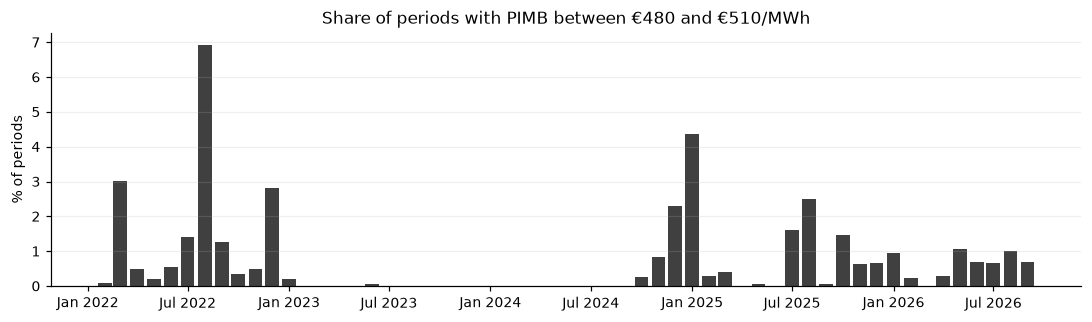

pimb_eur
488.00    57
490.00    49
489.00    45
418.00    37
481.00    36
438.00    36
426.00    34
408.00    34
401.00    33
420.00    32
Name: periods, dtype: int64

In [23]:
near_cap = p.between(480, 510).groupby(p.index.tz_convert(None).to_period("M")).mean() * 100

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(near_cap.index.to_timestamp(), near_cap.values, width=25, color="0.25")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("% of periods")
ax.set_title("Share of periods with PIMB between €480 and €510/MWh")
finish(fig, "pimb_ceiling")
p[p > 400].round(0).value_counts().head(10).rename("periods")

## 8. Notes

**Decisions recorded in this notebook**

- Spikes are defined on the PIMB–DA spread; the forecasting target remains the PIMB.
- Primary definition: trailing 90-day quantiles (99th/1st for rare events, 95th/5th for frequent events), with a 30-day warm-up from 1 February 2022.
- Benchmark: fixed whole-sample quantiles. Sensitivity: 30-, 60- and 365-day windows, and the economic floor.
- A single threshold applies to all hours of the day.

**Open questions**

- Mechanism behind the ~€490/MWh ceiling from late 2024.
- Value of the economic floor $c$, to be set with reference to a trading decision.

## References

- Christensen, T.M., Hurn, A.S. and Lindsay, K.A. (2009). It never rains but it pours: Modeling the persistence of spikes in electricity prices. *The Energy Journal*, 30(1), 25–48.
- Christensen, T.M., Hurn, A.S. and Lindsay, K.A. (2012). Forecasting spikes in electricity prices. *International Journal of Forecasting*, 28(2), 400–411.
- Cornell, C., Dinh, N.T. and Pourmousavi, S.A. (2023). A probabilistic forecast methodology for volatile electricity prices in the Australian National Electricity Market. arXiv:2311.07289.
- Hagfors, L.I., Kamperud, H.H., Paraschiv, F., Prokopczuk, M., Sator, A. and Westgaard, S. (2016). Prediction of extreme price occurrences in the German day-ahead electricity market. *Quantitative Finance*, 16(12), 1929–1948.
- Hubert, E., Lolas, D. and Sircar, R. Trading Electrons: Predicting DART Spread Spikes in ISO Electricity Markets. arXiv:2601.05085.
- Janczura, J., Trück, S., Weron, R. and Wolff, R.C. (2013). Identifying spikes and seasonal components in electricity spot price data: A guide to robust modeling. *Energy Economics*, 38, 96–110.
- Lee, S.S. and Mykland, P.A. (2008). Jumps in financial markets: A new nonparametric test and jump dynamics. *Review of Financial Studies*, 21(6), 2535–2563.